# Distribution Network: Minimum-Cost Transshipment

**Business question:** Two factories (Denver, Los Angeles) ship through two distribution centres (Chicago, Memphis) to two markets (New York, Boston). **How should product flow through the network to meet demand at the lowest shipping cost, and where is the network constrained?**

**Approach:** a minimum-cost network flow (linear program) in Python with Gurobi.
- Supply limits at each factory, flow balance at each DC (inflow = outflow), exact demand at each market.
- Shadow prices (duals) on the constraints show the value of extra capacity, which is what a manager actually needs for an investment decision.

In [1]:
import gurobipy as gp
from gurobipy import GRB, quicksum
import pandas as pd
import matplotlib.pyplot as plt

# Quiet Gurobi environment (no licence banner or solver log in the output)
env = gp.Env(empty=True)
env.setParam("OutputFlag", 0)
_ = env.start()

In [2]:
factories = ["Denver", "LA"]
dcs       = ["Chicago", "Memphis"]
markets   = ["NY", "Boston"]

supply = {"Denver": 200, "LA": 150}   # units
demand = {"NY": 130, "Boston": 130}   # units
cost = {  # $ per unit on each lane
    ("Denver", "Chicago"): 6, ("Denver", "Memphis"): 8,
    ("LA", "Chicago"): 12,    ("LA", "Memphis"): 10,
    ("Chicago", "NY"): 4,     ("Chicago", "Boston"): 5,
    ("Memphis", "NY"): 5,     ("Memphis", "Boston"): 7,
}
lanes = list(cost)

m = gp.Model("Transshipment", env=env)
x = m.addVars(lanes, lb=0, name="ship")
m.setObjective(quicksum(cost[a] * x[a] for a in lanes), GRB.MINIMIZE)
sup = m.addConstrs((quicksum(x[f, d] for d in dcs) <= supply[f] for f in factories), name="supply")
bal = m.addConstrs((quicksum(x[f, d] for f in factories) == quicksum(x[d, k] for k in markets) for d in dcs), name="balance")
dem = m.addConstrs((quicksum(x[d, k] for d in dcs) == demand[k] for k in markets), name="demand")
m.optimize()

print(f"Minimum total shipping cost: ${m.ObjVal:,.0f}\n")
flows = pd.DataFrame([{"From": a[0], "To": a[1], "Units": x[a].X, "Cost/unit": cost[a]}
                      for a in lanes if x[a].X > 1e-6])
print(flows.to_string(index=False))
print("\nShadow price of one extra unit of factory capacity:")
for f in factories:
    print(f"  {f:<7} ${sup[f].Pi:,.2f}  (used {sum(x[f, d].X for d in dcs):.0f} of {supply[f]})")

Minimum total shipping cost: $3,030

   From      To  Units  Cost/unit
 Denver Chicago  200.0          6
     LA Memphis   60.0         10
Chicago      NY   70.0          4
Chicago  Boston  130.0          5
Memphis      NY   60.0          5

Shadow price of one extra unit of factory capacity:
  Denver  $-5.00  (used 200 of 200)
  LA      $0.00  (used 60 of 150)


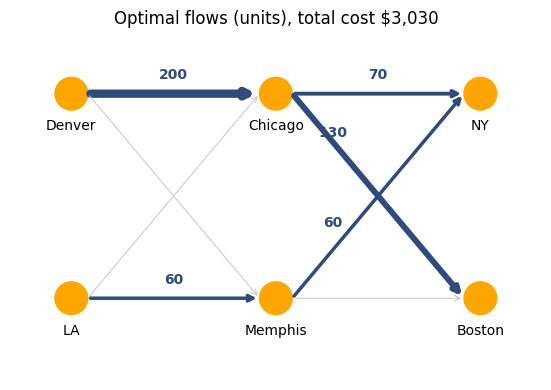

In [3]:
import matplotlib.patches as mpatches
pos = {"Denver": (0, 1), "LA": (0, 0), "Chicago": (1, 1), "Memphis": (1, 0), "NY": (2, 1), "Boston": (2, 0)}
fig, ax = plt.subplots(figsize=(8, 4))
for a in lanes:
    (x0, y0), (x1, y1) = pos[a[0]], pos[a[1]]
    used = x[a].X > 1e-6
    ax.annotate("", xy=(x1 - 0.08, y1), xytext=(x0 + 0.08, y0),
                arrowprops=dict(arrowstyle="->", lw=1 + x[a].X / 40 if used else 0.8,
                                color="#2f4b7c" if used else "#cccccc"))
    if used:
        f = 0.5 if y0 == y1 else 0.28
        ax.text(x0 + f * (x1 - x0), y0 + f * (y1 - y0) + 0.07, f"{x[a].X:.0f}", ha="center", color="#2f4b7c", fontweight="bold")
for n, (px, py) in pos.items():
    ax.add_patch(mpatches.Circle((px, py), 0.08, color="#ffa600"))
    ax.text(px, py - 0.18, n, ha="center")
ax.set_xlim(-0.3, 2.3); ax.set_ylim(-0.4, 1.3); ax.set_aspect("equal"); ax.axis("off")
ax.set_title(f"Optimal flows (units), total cost ${m.ObjVal:,.0f}")
plt.tight_layout(); plt.savefig("images/transshipment_flows.png", dpi=150); plt.show()

## Findings

- **Denver is the workhorse.** All of Denver's 200 units go through Chicago, the cheapest lane in the network; Los Angeles only tops up the shortfall through Memphis.
- **Denver capacity is the bottleneck, and it has a price.** Its shadow price is -$5: every extra unit of Denver capacity would cut network cost by **$5**, a direct input to any capacity-expansion business case. Total cost today: **$3,030**.
- **Los Angeles has slack.** It uses only 60 of 150 units, so the network can absorb demand growth without new plant investment, at a higher marginal cost.

**Skills shown:** network-flow modelling, linear programming, duality/shadow prices for capacity decisions, Gurobi/Python.